In [3]:
%pip install -r "/Users/nielspeters/Library/CloudStorage/OneDrive-KULeuven/MASTER 2/R&D project/requirements.txt"


  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 68.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.3/48.3 MB 81.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pandas]2m2/3 [pandas]python-headless]
Note: you may need to restart the kernel to use updated packages.


In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Video, display



def find_project_root(start: Path = Path.cwd()) -> Path:
    """Find the repository root from either the root or notebooks directory."""
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "README.md").exists() and (candidate / "data").exists():
            return candidate
    raise FileNotFoundError("Could not locate the project root.")


PROJECT_ROOT = find_project_root()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
CLIP_DIR = PROJECT_ROOT / "results" / "clips"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
CLIP_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")

Project root: /Users/nielspeters/Library/CloudStorage/OneDrive-KULeuven/MASTER 2/R&D project


## 1. Load and validate the training annotations

The search supports both the small local layout (`data/raw/EPIC_100_train.csv`) and the full VSC layout under `data/raw/EPIC-KITCHENS/annotations/`.

In [2]:
annotation_candidates = sorted(RAW_DIR.rglob("EPIC_100_train.csv"))
if not annotation_candidates:
    raise FileNotFoundError(
        "EPIC_100_train.csv was not found below data/raw. "
        "Download or copy the annotations before continuing."
    )

ANNOTATION_PATH = annotation_candidates[0]
annotations = pd.read_csv(ANNOTATION_PATH)

required_columns = {
    "narration_id", "participant_id", "video_id",
    "start_timestamp", "stop_timestamp", "narration",
    "verb", "verb_class", "noun", "noun_class",
}
missing_columns = required_columns.difference(annotations.columns)
if missing_columns:
    raise ValueError(f"Missing annotation columns: {sorted(missing_columns)}")

print(f"Loaded: {ANNOTATION_PATH.relative_to(PROJECT_ROOT)}")
print(f"Rows: {len(annotations):,}")
print(f"Participants: {annotations['participant_id'].nunique()}")
print(f"Videos: {annotations['video_id'].nunique()}")
print(f"Verb classes: {annotations['verb_class'].nunique()}")
print(f"Noun classes: {annotations['noun_class'].nunique()}")

annotations.head()

Loaded: data/raw/EPIC_100_train.csv
Rows: 67,217
Participants: 32
Videos: 495
Verb classes: 97
Noun classes: 289


,narration_id,participant_id,video_id,narration_timestamp,start_timestamp,stop_timestamp,start_frame,stop_frame,narration,verb,verb_class,noun,noun_class,all_nouns,all_noun_classes
0,P01_01_0,P01,P01_01,00:00:01.089,00:00:00.14,00:00:03.37,8,202,open door,open,3,door,3,['door'],[3]
1,P01_01_1,P01,P01_01,00:00:02.629,00:00:04.37,00:00:06.17,262,370,turn on light,turn-on,6,light,114,['light'],[114]
2,P01_01_10,P01,P01_01,00:00:23.340,00:00:24.97,00:00:26.20,1498,1572,open drawer,open,3,drawer,8,['drawer'],[8]
3,P01_01_100,P01,P01_01,00:07:57.919,00:07:59.75,00:08:00.88,28785,28852,take cup,take,0,cup,13,['cup'],[13]
4,P01_01_101,P01,P01_01,00:08:00.020,00:08:01.47,00:08:02.21,28888,28932,open cupboard,open,3,cupboard,3,['cupboard'],[3]


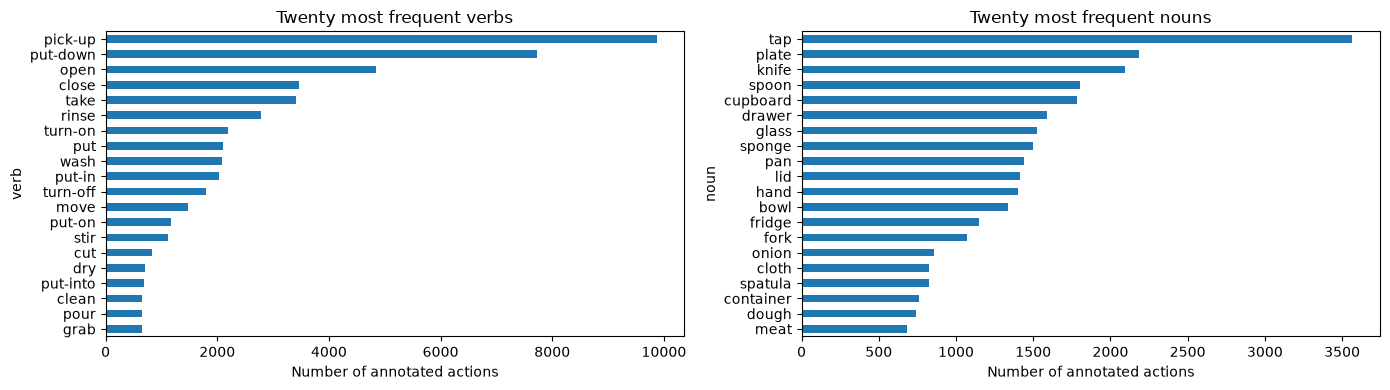

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
annotations['verb'].value_counts().head(20).sort_values().plot.barh(
    ax=axes[0], title="Twenty most frequent verbs"
)
annotations['noun'].value_counts().head(20).sort_values().plot.barh(
    ax=axes[1], title="Twenty most frequent nouns"
)
for axis in axes:
    axis.set_xlabel("Number of annotated actions")
plt.tight_layout()

The dataset seems strongly imbalanced, some actions appear far more then others

## 2. Match annotations to locally available videos

On the laptop only a few example videos may be present. On VSC this should find the complete downscaled collection recursively.

In [ ]:
video_files = sorted(
    path for path in RAW_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() == ".mp4"
)
video_by_id = {path.stem.upper(): path for path in video_files}

available_annotations = annotations[
    annotations['video_id'].str.upper().isin(video_by_id)
].copy()

print(f"Video files found: {len(video_files):,}")
print(f"Matched annotation rows: {len(available_annotations):,}")
if available_annotations.empty:
    raise RuntimeError(
        "No annotation rows match the available videos. Check the data paths."
    )

available_annotations[[
    'narration_id', 'video_id', 'start_timestamp', 'stop_timestamp',
    'narration', 'verb', 'noun',
]].head(10)

## 3. Select and inspect one labelled sample

Change `SAMPLE_INDEX` to inspect a different matched annotation.

In [ ]:
SAMPLE_INDEX = 0
sample = available_annotations.iloc[SAMPLE_INDEX]
video_path = video_by_id[sample['video_id'].upper()]

display(sample[[
    'narration_id', 'participant_id', 'video_id',
    'start_timestamp', 'stop_timestamp', 'narration',
    'verb', 'verb_class', 'noun', 'noun_class',
]])
print(f"Video: {video_path.relative_to(PROJECT_ROOT)}")

In [ ]:
def timestamp_to_seconds(timestamp: str) -> float:
    """Convert an HH:MM:SS.s timestamp to seconds."""
    return pd.to_timedelta(timestamp).total_seconds()


def read_frame(path: Path, time_seconds: float) -> np.ndarray:
    """Read one RGB frame at approximately the requested timestamp."""
    capture = cv2.VideoCapture(str(path))
    if not capture.isOpened():
        raise RuntimeError(f"Could not open video: {path}")
    capture.set(cv2.CAP_PROP_POS_MSEC, time_seconds * 1000)
    success, frame = capture.read()
    capture.release()
    if not success:
        raise RuntimeError(f"Could not read frame at {time_seconds:.2f}s")
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)


start_seconds = timestamp_to_seconds(sample['start_timestamp'])
stop_seconds = timestamp_to_seconds(sample['stop_timestamp'])
middle_seconds = (start_seconds + stop_seconds) / 2
frame = read_frame(video_path, middle_seconds)

plt.figure(figsize=(9, 5))
plt.imshow(frame)
plt.title(
    f"{sample['narration']} | verb={sample['verb']} | noun={sample['noun']}"
)
plt.axis("off");

## 4. Extract the AR and STA clips

The STA observation uses five seconds of context when available and ends exactly one second before the labelled action begins. No frame from the one-second gap or target action is included.

In [ ]:
def extract_clip(
    source: Path, start: float, stop: float, destination: Path
) -> Path:
    """Extract an interval with OpenCV and return the generated MP4 path."""
    if start < 0 or stop <= start:
        raise ValueError(f"Invalid clip interval: start={start}, stop={stop}")

    capture = cv2.VideoCapture(str(source))
    if not capture.isOpened():
        raise RuntimeError(f"Could not open video: {source}")

    fps = capture.get(cv2.CAP_PROP_FPS)
    width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
    if not fps or width <= 0 or height <= 0:
        capture.release()
        raise RuntimeError(f"Invalid video metadata for {source}")

    destination.parent.mkdir(parents=True, exist_ok=True)
    writer = cv2.VideoWriter(
        str(destination),
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (width, height),
    )
    if not writer.isOpened():
        capture.release()
        raise RuntimeError("Could not initialize the MP4 writer.")

    capture.set(cv2.CAP_PROP_POS_MSEC, start * 1000)
    frames_written = 0
    while capture.get(cv2.CAP_PROP_POS_MSEC) < stop * 1000:
        success, frame = capture.read()
        if not success:
            break
        writer.write(frame)
        frames_written += 1

    capture.release()
    writer.release()
    if frames_written == 0:
        destination.unlink(missing_ok=True)
        raise RuntimeError("No frames were written for the requested interval.")
    return destination


ar_path = extract_clip(
    video_path,
    start_seconds,
    stop_seconds,
    CLIP_DIR / f"{sample['narration_id']}_ar.mp4",
)

STA_GAP_SECONDS = 1.0
STA_CONTEXT_SECONDS = 5.0
sta_stop_seconds = start_seconds - STA_GAP_SECONDS
sta_start_seconds = max(0.0, sta_stop_seconds - STA_CONTEXT_SECONDS)
if sta_stop_seconds <= sta_start_seconds:
    raise ValueError(
        "This action starts too early to create a non-empty STA observation. "
        "Choose another sample or implement padding for early events."
    )

sta_path = extract_clip(
    video_path,
    sta_start_seconds,
    sta_stop_seconds,
    CLIP_DIR / f"{sample['narration_id']}_sta.mp4",
)

print(f"AR interval:  {start_seconds:.2f}s to {stop_seconds:.2f}s")
print(f"STA interval: {sta_start_seconds:.2f}s to {sta_stop_seconds:.2f}s")
print(f"Required gap: {start_seconds - sta_stop_seconds:.2f}s")

In [ ]:
print(f"AR clip — target action: {sample['narration']}")
display(Video(str(ar_path), embed=True))

print("STA clip — context only; predict the action shown above")
display(Video(str(sta_path), embed=True))

## 5. Create a reproducible participant-level split

A participant-level split avoids putting actions from the same participant in both training and validation. This gives a more realistic estimate of generalization to unseen participants than randomly splitting individual rows.

In [ ]:
RANDOM_SEED = 42
VALIDATION_FRACTION = 0.20

participants = np.array(sorted(annotations['participant_id'].unique()))
rng = np.random.default_rng(RANDOM_SEED)
shuffled_participants = rng.permutation(participants)
validation_count = max(1, round(len(participants) * VALIDATION_FRACTION))
validation_participants = set(shuffled_participants[:validation_count])

validation_annotations = annotations[
    annotations['participant_id'].isin(validation_participants)
].copy()
training_annotations = annotations[
    ~annotations['participant_id'].isin(validation_participants)
].copy()

assert set(training_annotations['participant_id']).isdisjoint(
    validation_annotations['participant_id']
)
assert len(training_annotations) + len(validation_annotations) == len(annotations)

split_summary = pd.DataFrame(
    {
        'rows': [len(training_annotations), len(validation_annotations)],
        'participants': [
            training_annotations['participant_id'].nunique(),
            validation_annotations['participant_id'].nunique(),
        ],
        'verb_classes': [
            training_annotations['verb_class'].nunique(),
            validation_annotations['verb_class'].nunique(),
        ],
        'noun_classes': [
            training_annotations['noun_class'].nunique(),
            validation_annotations['noun_class'].nunique(),
        ],
    },
    index=['train', 'validation'],
)
display(split_summary)
print("Validation participants:", sorted(validation_participants))

In [ ]:
train_path = PROCESSED_DIR / "EPIC_100_train_participant_split.csv"
validation_path = PROCESSED_DIR / "EPIC_100_validation_participant_split.csv"
training_annotations.to_csv(train_path, index=False)
validation_annotations.to_csv(validation_path, index=False)

print(f"Saved {len(training_annotations):,} training rows to {train_path}")
print(f"Saved {len(validation_annotations):,} validation rows to {validation_path}")

## Next steps

1. Review the validation participants and class coverage as a team.
2. Move reusable timestamp, indexing, and clip-loading logic into `src/data_processing.py`.
3. Replace generated preview clips with an on-the-fly frame sampler for model training.
4. Establish a simple pretrained-video baseline with separate verb and noun heads.